## Load Dataset

In [1]:
!pip install datasets
!pip install python-dotenv
!pip install pandas
!pip install seaborn

You should consider upgrading via the '/Users/mondra/git/uzh/text-speech-processing/.venv/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/mondra/git/uzh/text-speech-processing/.venv/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/mondra/git/uzh/text-speech-processing/.venv/bin/python3 -m pip install --upgrade pip' command.
You should consider upgrading via the '/Users/mondra/git/uzh/text-speech-processing/.venv/bin/python3 -m pip install --upgrade pip' command.


In [2]:
from data import load_gahd, load_gahd_raw

df = load_gahd_raw()
df_train, df_dev, df_test = load_gahd()

print(len(df_train), len(df_dev), len(df_test))

/Users/mondra/git/uzh/text-speech-processing/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


7701 1649 1646


In [3]:
print(df["text"].isna().sum(), (df["text"].str.strip() == "").sum())
print(df["text"].duplicated().sum()) # are there duplicates?
print(df.groupby("text")["split"].nunique().gt(1).sum()) # is there the same entry in > 1 split?

0 1
0
0


<Axes: xlabel='label', ylabel='proportion'>

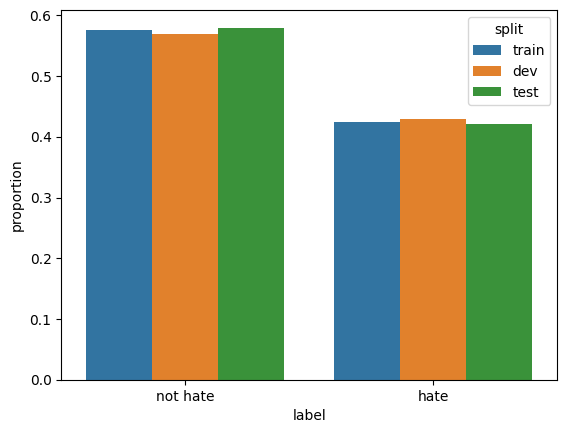

In [4]:
import seaborn as sns

plot_df = df.assign(label=df["label"].map({0: "not hate", 1: "hate"}))
prop = (plot_df.groupby("split")["label"]
        .value_counts(normalize=True)
        .rename("proportion")
        .reset_index())

sns.barplot(data=prop, x="label", y="proportion", hue="split",
            hue_order=["train", "dev", "test"])

Dataset is moderately balanced, there is 15% more data labelled as not hate.